# Section B: Question 1


# Part A

### importing libraries

In [1]:
import time
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from scipy import ndimage
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

### setting seeds

In [2]:
seeds = [0, 1, 2]      # 3 seeds
data_seed = 123        # for the 500 training images
split_seed = 42        # 400/100 split
shift_seed = 999       # shifted test set
epochs = 60            # maximum allowed
batch_size = 32

# for repeatable results
tf.config.experimental.enable_op_determinism()

### loading data

In [3]:
(x_all, y_all), (clean_x, clean_y) = cifar10.load_data()

# flatten to (N,)
y_all = y_all.flatten()
clean_y = clean_y.flatten()

# 50 images per class with a fixed seed -> train_small (500 images)
rng = np.random.RandomState(data_seed)
idx = np.concatenate([rng.choice(np.where(y_all == c)[0], 50, replace=False)
                      for c in range(10)])

train_x = x_all[idx]     # 500 training images
train_y = y_all[idx]

print("train_small:", train_x.shape, "class counts:", np.bincount(train_y))
print("clean_test: ", clean_x.shape)

train_small: (500, 32, 32, 3) class counts: [50 50 50 50 50 50 50 50 50 50]
clean_test:  (10000, 32, 32, 3)


### corruption code (builds the shifted test set)

In [4]:
def hidden_corruption(img, rng):
    # my own hidden corruption: random grayscale OR random channel swap
    if rng.rand() < 0.5:
        if rng.rand() < 0.5:
            gray = img.mean(axis=2, keepdims=True)
            img = np.repeat(gray, 3, axis=2)        # grayscale
        else:
            img = img[:, :, rng.permutation(3)]     # channel swap
    return img


def corrupt(img, rng):
    img = img.astype(np.float32)

    # random rotation up to +-25 degrees
    img = ndimage.rotate(img, rng.uniform(-25, 25), axes=(0, 1),
                         reshape=False, mode='nearest')

    # brightness and contrast change
    img = img * rng.uniform(0.5, 1.5) + rng.uniform(-50, 50)

    # blur on half of the images
    if rng.rand() < 0.5:
        s = rng.uniform(0.5, 1.5)
        img = ndimage.gaussian_filter(img, sigma=(s, s, 0))

    # gaussian noise
    img = img + rng.normal(0, 15, img.shape)

    # hidden corruption
    img = hidden_corruption(img, rng)

    # 16x16 black square = 25% of the image
    r, c = rng.randint(0, 17), rng.randint(0, 17)
    img[r:r+16, c:c+16, :] = 0

    return np.clip(img, 0, 255).astype(np.uint8)

shift_rng = np.random.RandomState(shift_seed)
shift_x = np.array([corrupt(im, shift_rng) for im in clean_x])
shift_y = clean_y.copy()

### splitting the dataset

In [10]:
# stratified split 40 train + 10 validation images per class
X_train, X_val, y_train, y_val = train_test_split(
    train_x, train_y, test_size=100, stratify=train_y, random_state=split_seed)

# raw 0-255 copy of the training images 
X_train_raw = X_train.astype('float32')

# scale pixels to 0-1
X_train = X_train / 255.0
X_val = X_val / 255.0
X_clean = clean_x / 255.0     
X_shift = shift_x / 255.0      

# one-hot labels 
y_train_oh = to_categorical(y_train, 10)
y_val_oh = to_categorical(y_val, 10)
clean_y_oh = to_categorical(clean_y, 10)
shift_y_oh = to_categorical(shift_y, 10)

print("train:", X_train.shape, "val:", X_val.shape)
print("train class counts:", np.bincount(y_train))
print("val class counts:  ", np.bincount(y_val))

train: (400, 32, 32, 3) val: (100, 32, 32, 3)
train class counts: [40 40 40 40 40 40 40 40 40 40]
val class counts:   [10 10 10 10 10 10 10 10 10 10]


### inception-style module

In [6]:
def inception_module(x, f1, f3_red, f3, f5_red, f5, f_pool):
    # branch 1: 1x1 conv
    b1 = layers.Conv2D(f1, (1, 1), padding='same', activation='relu')(x)

    # branch 2: 1x1 reduction, then 3x3 conv
    b2 = layers.Conv2D(f3_red, (1, 1), padding='same', activation='relu')(x)
    b2 = layers.Conv2D(f3, (3, 3), padding='same', activation='relu')(b2)

    # branch 3: 1x1 reduction, then 5x5 conv
    b3 = layers.Conv2D(f5_red, (1, 1), padding='same', activation='relu')(x)
    b3 = layers.Conv2D(f5, (5, 5), padding='same', activation='relu')(b3)

    # branch 4: max pool, then 1x1 conv
    b4 = layers.MaxPooling2D((3, 3), strides=1, padding='same')(x)
    b4 = layers.Conv2D(f_pool, (1, 1), padding='same', activation='relu')(b4)

    # join all branches
    return layers.Concatenate()([b1, b2, b3, b4])

### baseline model

In [7]:
def build_model():
    inputs = layers.Input(shape=(32, 32, 3))

    # LeNet-style block
    x = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(inputs)
    x = layers.MaxPooling2D((2, 2))(x)                 # 16x16

    # Inception module
    x = inception_module(x, 16, 16, 24, 8, 8, 8)
    x = layers.MaxPooling2D((2, 2))(x)                 # 8x8

    # another conv block
    x = layers.Conv2D(96, (3, 3), padding='same', activation='relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)                 # 4x4

    # classifier
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(10, activation='softmax')(x)

    model = models.Model(inputs, outputs)
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

model = build_model()
model.summary()
assert sum(int(np.prod(w.shape)) for w in model.trainable_weights) <= 1_000_000   # parameter limit check

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d (Conv2D)               │ (None, 32, 32, 32)        │             896 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d (MaxPooling2D)  │ (None, 16, 16, 32)        │               0 │ conv2d[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_2 (Conv2D)             │ (None, 16, 16, 16)        │             528 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_4 (Conv2D)             │ (None, 16, 16, 8)         │             264 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_1               │ (None, 16, 16, 32)        │               0 │ max_pooling2d[0][0]        │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_1 (Conv2D)             │ (None, 16, 16, 16)        │             528 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_3 (Conv2D)             │ (None, 16, 16, 24)        │           3,480 │ conv2d_2[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_5 (Conv2D)             │ (None, 16, 16, 8)         │           1,608 │ conv2d_4[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_6 (Conv2D)             │ (None, 16, 16, 8)         │             264 │ max_pooling2d_1[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate (Concatenate)     │ (None, 16, 16, 56)        │               0 │ conv2d_1[0][0],            │
│                               │                           │                 │ conv2d_3[0][0],            │
│                               │                           │                 │ conv2d_5[0][0],            │
│                               │                           │                 │ conv2d_6[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_2               │ (None, 8, 8, 56)          │               0 │ concatenate[0][0]          │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_7 (Conv2D)             │ (None, 8, 8, 96)          │          48,480 │ max_pooling2d_2[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_3               │ (None, 4, 4, 96)          │               0 │ conv2d_7[0][0]             │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 57,018 (222.73 KB)

 Trainable params: 57,018 (222.73 KB)

 Non-trainable params: 0 (0.00 B)

### training with 3 seeds (no augmentation)

In [9]:
results = {"train": [], "val": [], "clean": [], "shifted": []}
histories = {}

for seed in seeds:
    tf.keras.utils.set_random_seed(seed)
    model = build_model()

    # no augmentation in part A
    history = model.fit(X_train, y_train,
                        epochs=epochs,
                        batch_size=batch_size,
                        validation_data=(X_val, y_val),
                        verbose=0)
    histories[seed] = history.history

    # part A explicitly asks; nothing is tuned from them
    train_acc = model.evaluate(X_train, y_train, verbose=0)[1]
    val_acc = model.evaluate(X_val, y_val, verbose=0)[1]
    clean_acc = model.evaluate(X_clean, clean_y, verbose=0)[1]
    shift_acc = model.evaluate(X_shift, shift_y, verbose=0)[1]

    results["train"].append(train_acc)
    results["val"].append(val_acc)
    results["clean"].append(clean_acc)
    results["shifted"].append(shift_acc)

    print(f"Seed {seed}: train={train_acc:.4f}  val={val_acc:.4f}  "
          f"clean={clean_acc:.4f}  shifted={shift_acc:.4f}")

Seed 0: train=0.6850  val=0.4100  clean=0.3874  shifted=0.1885
Seed 1: train=0.6225  val=0.4000  clean=0.3869  shifted=0.1684
Seed 2: train=0.6350  val=0.3900  clean=0.3814  shifted=0.1777


### results (mean ± std)

In [11]:
print("Seeds:", seeds, "| data seed:", data_seed, "| split seed:", split_seed, "| shift seed:", shift_seed)
print("Baseline (no augmentation), mean ± std over 3 seeds\n")

for name in ["train", "val", "clean", "shifted"]:
    arr = np.array(results[name]) * 100
    print(f"{name:>8} accuracy: {arr.mean():.2f} ± {arr.std():.2f} %")

Seeds: [0, 1, 2] | data seed: 123 | split seed: 42 | shift seed: 999
Baseline (no augmentation), mean ± std over 3 seeds

   train accuracy: 64.75 ± 2.70 %
     val accuracy: 40.00 ± 0.82 %
   clean accuracy: 38.52 ± 0.27 %
 shifted accuracy: 17.82 ± 0.82 %


### learning curves

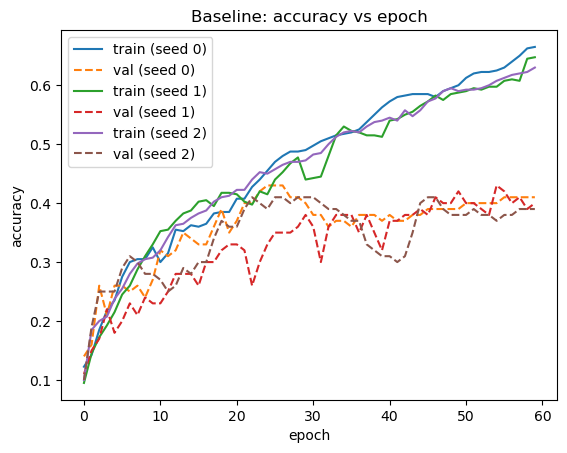

In [12]:
# accuracy curves
for seed in seeds:
    plt.plot(histories[seed]['accuracy'], label=f'train (seed {seed})')
    plt.plot(histories[seed]['val_accuracy'], linestyle='--', label=f'val (seed {seed})')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.title('Baseline: accuracy vs epoch')
plt.legend()
plt.show()

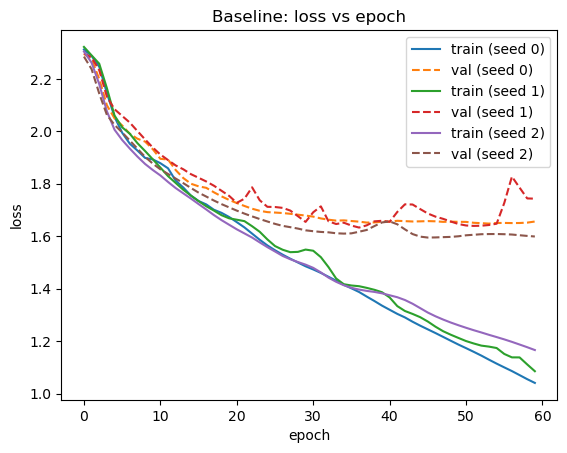

In [13]:
# loss curves
for seed in seeds:
    plt.plot(histories[seed]['loss'], label=f'train (seed {seed})')
    plt.plot(histories[seed]['val_loss'], linestyle='--', label=f'val (seed {seed})')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('Baseline: loss vs epoch')
plt.legend()
plt.show()

## Conclusion

The baseline reaches 64% on the 400 training images but only 40% on the 100 validation images,
a gap of 24 points, so it **overfits** the tiny training set. On the clean test set it scores
38%, but on the shifted test set it drops to 17.82 ± 0.82 %, a further loss of 21 points.
The clean and shifted test sets contain the same images, so this extra loss cannot come from overfitting.
It is **covariate shift**: rotation, brightness/contrast changes, blur, noise, colour changes and occlusion
move the inputs away from the clean training distribution, which the network never saw.
The failure is therefore **both**: overfitting (train vs validation/clean) and covariate shift (clean vs shifted).


# Part B

### Answers to the Part B questions

**1. Would vertical flip help or hurt?**
It would hurt. CIFAR-10 objects have a fixed upright orientation: sky is above, ground below, so vertical flips totally shift the image and they destroy orientation understanding (e.g. the horizon, legs below the body). The main thing that help models to tell classes apart is destrotyed. Horizontal flip is fine because a mirrored cat is still a understandable cat.

**2. Rotation up to ±90° while the test only has ±25°: what is the trade-off?**
The wider rotation range includes the rotations seen during testing, but it also creates many images with rotations that never appear in the test data. This makes the model spend time learning from unusual angles and empty or reflected corners, which makes learning harder. Since the model is small and we only have 400 images, this can reduce its accuracy on normal and slightly rotated images. A smaller rotation range of around ±25–30° would be a better choice because it provides enough variety without making the training too difficult.

**3. Why can too much augmentation reduce accuracy on such a small model?**
A small network with fewer than 200k parameters has limited learning capacity. Strong data augmentation makes the training images too varied and difficult, so the model may struggle to learn properly. As a result, training accuracy stays low, and validation accuracy stops improving or even decreases. Very strong transformations can also hide important features of an image, such as when an object is heavily covered or rotated. This can confuse the model because it becomes harder to identify the correct class. Since we only have 400 images and 60 training epochs, the network may not get enough time to learn all these variations.

### extra augmentations (contrast, blur, noise, colour, cutout)

ImageDataGenerator already does rotation, shifts, zoom, flip and brightness, but not the others.

In [14]:
def extra_augment(img):
    # img is a 32x32x3 image with values 0-255

    # random contrast
    factor = np.random.uniform(0.7, 1.3)
    mean = img.mean()
    img = (img - mean) * factor + mean

    # blur on 30% of images
    if np.random.rand() < 0.3:
        s = np.random.uniform(0.5, 1.2)
        img = ndimage.gaussian_filter(img, sigma=(s, s, 0))

    # random noise
    img = img + np.random.normal(0, 10, img.shape)

    # grayscale on 20% of images
    if np.random.rand() < 0.2:
        gray = img.mean(axis=2, keepdims=True)
        img = np.repeat(gray, 3, axis=2)

    # swap colour channels on 20% of images
    if np.random.rand() < 0.2:
        img = img[:, :, np.random.permutation(3)]

    # black 16x16 square (Cutout) on 50% of images
    if np.random.rand() < 0.5:
        r = np.random.randint(0, 17)
        c = np.random.randint(0, 17)
        img[r:r+16, c:c+16, :] = 0

    # keep values in 0-255, then scale to 0-1
    img = np.clip(img, 0, 255)
    return img / 255.0

### image generator (applied on the fly, training data only)

In [15]:
datagen = ImageDataGenerator(
    rotation_range=25,              # rotate up to 25 degrees
    width_shift_range=0.1,          # shift left/right by 10%
    height_shift_range=0.1,         # shift up/down by 10%
    zoom_range=0.1,                 # zoom in/out by 10%
    horizontal_flip=True,           # only horizontal flip (vertical flip would hurt)
    brightness_range=(0.6, 1.4),    # darker / brighter
    fill_mode='reflect',
    preprocessing_function=extra_augment
)

### looking at augmented images

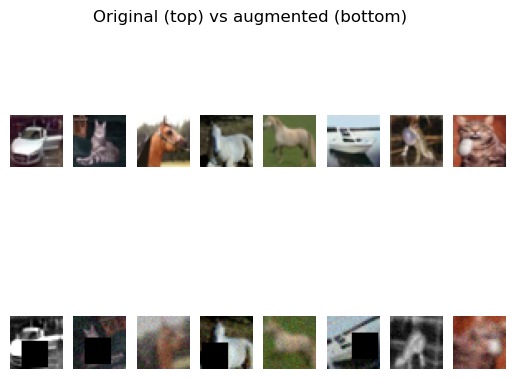

In [16]:
tf.keras.utils.set_random_seed(0)

# one batch of 8 augmented images
batch_x, batch_y = next(datagen.flow(X_train_raw, y_train, batch_size=8, shuffle=False))

for i in range(8):
    plt.subplot(2, 8, i + 1)
    plt.imshow(X_train[i])
    plt.axis('off')
    plt.subplot(2, 8, i + 9)
    plt.imshow(batch_x[i])
    plt.axis('off')

plt.suptitle('Original (top) vs augmented (bottom)')
plt.show()

### training with augmentation (3 seeds, baseline network)

In [17]:
aug_results = {"train": [], "val": []}
aug_histories = {}

for seed in seeds:
    tf.keras.utils.set_random_seed(seed)
    model = build_model()

    # augmentation is applied on the fly, only on training data
    history = model.fit(
        datagen.flow(X_train_raw, y_train, batch_size=batch_size, seed=seed),
        epochs=epochs,
        validation_data=(X_val, y_val),   # validation is NOT augmented
        verbose=0)
    aug_histories[seed] = history.history

    aug_results["train"].append(model.evaluate(X_train, y_train, verbose=0)[1])
    aug_results["val"].append(model.evaluate(X_val, y_val, verbose=0)[1])
    print(f"Seed {seed}: train={aug_results['train'][-1]:.3f}  val={aug_results['val'][-1]:.3f}")

Seed 0: train=0.452  val=0.340
Seed 1: train=0.442  val=0.350
Seed 2: train=0.410  val=0.370


### results (mean ± std)

In [18]:
print("with augmentation, mean ± std over 3 seeds\n")
for name in ["train", "val"]:
    arr = np.array(aug_results[name]) * 100
    print(f"{name:>8} accuracy: {arr.mean():.2f} ± {arr.std():.2f} %")

with augmentation, mean ± std over 3 seeds

   train accuracy: 43.50 ± 1.81 %
     val accuracy: 35.33 ± 1.25 %


### learning curves

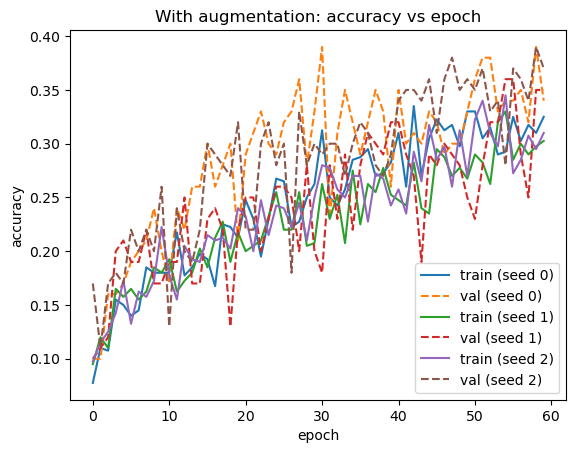

In [19]:
for seed in seeds:
    plt.plot(aug_histories[seed]['accuracy'], label=f'train (seed {seed})')
    plt.plot(aug_histories[seed]['val_accuracy'], linestyle='--', label=f'val (seed {seed})')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.title('With augmentation: accuracy vs epoch')
plt.legend()
plt.show()

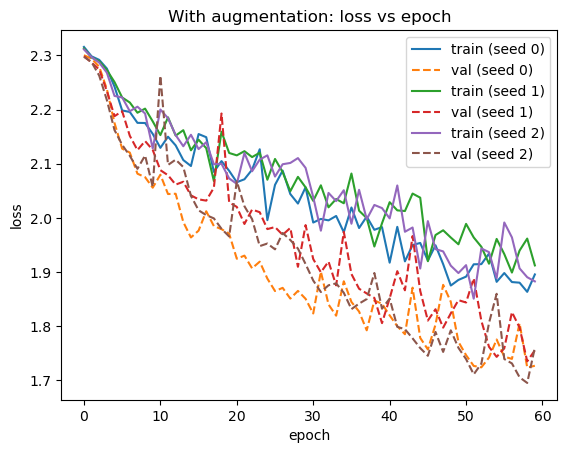

In [20]:
for seed in seeds:
    plt.plot(aug_histories[seed]['loss'], label=f'train (seed {seed})')
    plt.plot(aug_histories[seed]['val_loss'], linestyle='--', label=f'val (seed {seed})')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('With augmentation: loss vs epoch')
plt.legend()
plt.show()

# Conclusion

I used on-the-fly augmentation (rotation up to ±25°, ±10% shifts, ±10% zoom etc). With the baseline network, training accuracy changed from 64% to 43% and validation accuracy from 40% to 35% (train-validation gap 8 point). This means overfitting was reduced to some point but the overall accuracy was compromised. This shows that augmentation alone is not the good approach for such a small network. we need regularization methods as well

# Part C

### inception module with weight decay

In [21]:
reg = regularizers.l2(1e-5)    # weight decay

def inception_module_reg(x, f1, f3_red, f3, f5_red, f5, f_pool):
    b1 = layers.Conv2D(f1, (1, 1), padding='same', activation='relu', kernel_regularizer=reg)(x)

    b2 = layers.Conv2D(f3_red, (1, 1), padding='same', activation='relu', kernel_regularizer=reg)(x)
    b2 = layers.Conv2D(f3, (3, 3), padding='same', activation='relu', kernel_regularizer=reg)(b2)

    b3 = layers.Conv2D(f5_red, (1, 1), padding='same', activation='relu', kernel_regularizer=reg)(x)
    b3 = layers.Conv2D(f5, (5, 5), padding='same', activation='relu', kernel_regularizer=reg)(b3)

    b4 = layers.MaxPooling2D((3, 3), strides=1, padding='same')(x)
    b4 = layers.Conv2D(f_pool, (1, 1), padding='same', activation='relu', kernel_regularizer=reg)(b4)

    return layers.Concatenate()([b1, b2, b3, b4])

### model with BatchNorm, Dropout, weight decay and label smoothing 

In [22]:
def build_model_reg(label_smoothing=0.1):
    inputs = layers.Input(shape=(32, 32, 3))

    # Block 1 Conv -> BatchNorm -> ReLU
    x = layers.Conv2D(32, (3, 3), padding='same', kernel_regularizer=reg)(inputs)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(64, (3, 3), padding='same', kernel_regularizer=reg)(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)                 # 16x16

    # Inception module + BatchNorm
    x = inception_module_reg(x, 32, 32, 48, 16, 24, 16)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.MaxPooling2D((2, 2))(x)                 # 8x8

    # Block 3
    x = layers.Conv2D(128, (3, 3), padding='same', kernel_regularizer=reg)(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)                 # 4x4

    # Classifier: Dropout goes here, near the output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(10, activation='softmax', kernel_regularizer=reg)(x)

    model = models.Model(inputs, outputs)
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss=CategoricalCrossentropy(label_smoothing=label_smoothing),
                  metrics=['accuracy'])
    return model

model = build_model_reg()
model.summary()
n_trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print("Trainable parameters:", n_trainable)
assert n_trainable <= 1_000_000

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)    │ (None, 32, 32, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_64 (Conv2D)            │ (None, 32, 32, 32)        │             896 │ input_layer_8[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 32, 32, 32)        │             128 │ conv2d_64[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation (Activation)       │ (None, 32, 32, 32)        │               0 │ batch_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_65 (Conv2D)            │ (None, 32, 32, 64)        │          18,496 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_1         │ (None, 32, 32, 64)        │             256 │ conv2d_65[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_1 (Activation)     │ (None, 32, 32, 64)        │               0 │ batch_normalization_1[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_32              │ (None, 16, 16, 64)        │               0 │ activation_1[0][0]         │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_67 (Conv2D)            │ (None, 16, 16, 32)        │           2,080 │ max_pooling2d_32[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_69 (Conv2D)            │ (None, 16, 16, 16)        │           1,040 │ max_pooling2d_32[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_33              │ (None, 16, 16, 64)        │               0 │ max_pooling2d_32[0][0]     │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_66 (Conv2D)            │ (None, 16, 16, 32)        │           2,080 │ max_pooling2d_32[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_68 (Conv2D)            │ (None, 16, 16, 48)        │          13,872 │ conv2d_67[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_70 (Conv2D)            │ (None, 16, 16, 24)        │           9,624 │ conv2d_69[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_71 (Conv2D)            │ (None, 16, 16, 16)        │           1,040 │ max_pooling2d_33[0][0]     │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 190,162 (742.82 KB)

 Trainable params: 189,474 (740.13 KB)

 Non-trainable params: 688 (2.69 KB)

Trainable parameters: 189474


### learning-rate schedule and early stopping (validation loss only)

In [24]:
def make_callbacks():
    # halfthe learning rate if validation loss does not improve for 7 epochs
    lr_schedule = ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                    patience=7, min_lr=1e-5, verbose=0)
    # stop if validation loss does not improve for 25 epochs, keep the best weights
    early_stop = EarlyStopping(monitor='val_loss', patience=25,
                               restore_best_weights=True, verbose=0)
    return [lr_schedule, early_stop]

### training with 3 seeds: augmentation + regularization

In [25]:
reg_results = {"train": [], "val": [], "epochs_run": []}
reg_histories = {}

for seed in seeds:
    tf.keras.utils.set_random_seed(seed)
    model = build_model_reg(0.1)

    history = model.fit(
        datagen.flow(X_train_raw, y_train_oh, batch_size=batch_size, seed=seed),
        epochs=epochs,
        validation_data=(X_val, y_val_oh),
        callbacks=make_callbacks(),
        verbose=0)
    reg_histories[seed] = history.history

    reg_results["train"].append(model.evaluate(X_train, y_train_oh, verbose=0)[1])
    reg_results["val"].append(model.evaluate(X_val, y_val_oh, verbose=0)[1])
    reg_results["epochs_run"].append(len(history.history['loss']))
    print(f"Seed {seed}: epochs run={reg_results['epochs_run'][-1]}  "
          f"train={reg_results['train'][-1]:.3f}  val={reg_results['val'][-1]:.3f}")

Seed 0: epochs run=60  train=0.663  val=0.430
Seed 1: epochs run=60  train=0.600  val=0.500
Seed 2: epochs run=60  train=0.673  val=0.470


### results (mean ± std)

In [26]:
print("Augmentation + regularization, mean ± std over 3 seeds\n")
for name in ["train", "val"]:
    arr = np.array(reg_results[name]) * 100
    print(f"{name:>8} accuracy: {arr.mean():.2f} ± {arr.std():.2f} %")

Augmentation + regularization, mean ± std over 3 seeds

   train accuracy: 64.50 ± 3.21 %
     val accuracy: 46.67 ± 2.87 %


### learning curves

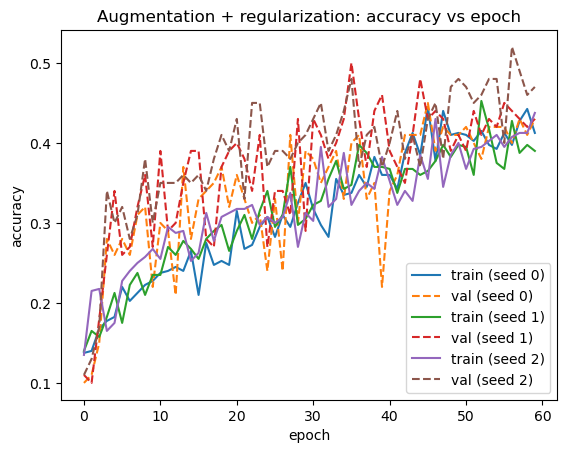

In [27]:
for seed in seeds:
    plt.plot(reg_histories[seed]['accuracy'], label=f'train (seed {seed})')
    plt.plot(reg_histories[seed]['val_accuracy'], linestyle='--', label=f'val (seed {seed})')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.title('Augmentation + regularization: accuracy vs epoch')
plt.legend()
plt.show()

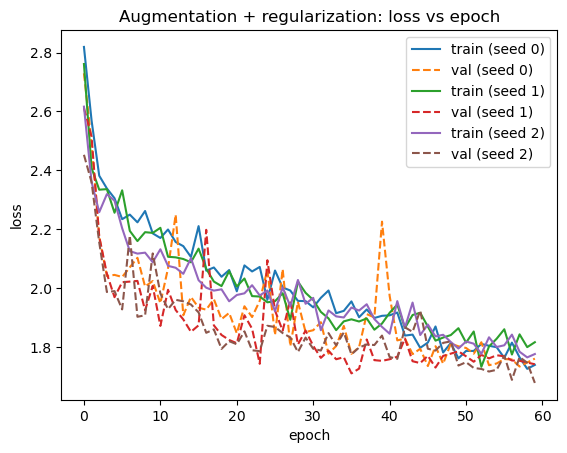

In [28]:
for seed in seeds:
    plt.plot(reg_histories[seed]['loss'], label=f'train (seed {seed})')
    plt.plot(reg_histories[seed]['val_loss'], linestyle='--', label=f'val (seed {seed})')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('Augmentation + regularization: loss vs epoch')
plt.legend()
plt.show()

## Justification of each technique

**Batch Normalization (BatchNorm):** It is added after each convolution layer, before ReLU, and after the Inception module. It keeps the values going into the next layer at a more stable scale, which helps the model train faster and more smoothly. It is useful here because data augmentation changes the brightness and contrast of images.

**Weight Decay (L2):** It is applied to all convolution and dense layer weights. It prevents the weights from becoming too large, which helps the model learn general patterns instead of memorizing the 400 training images.

**Dropout (0.3):** It is placed after global average pooling and before the output layer. This part of the model is more likely to overfit because it combines the learned features to make the final prediction. Dropout randomly turns off some activations during training, helping the model avoid relying too much on specific features. It is not used in the early convolution layers because this could make learning harder for a small model.

**Learning Rate Schedule:** It reduces the learning rate by half when the validation loss stops improving. This allows the model to learn quickly at first and then make smaller updates when it gets closer to a good result.

**Early Stopping:** It stops training if the validation loss does not improve for 25 epochs and restores the model's best weights. This prevents the model from continuing to train when it is no longer improving. Only validation data is used for this decision, not test data.

**Label Smoothing (0.1):** It makes the target labels slightly softer instead of using strict 0 and 1 values. This helps prevent the model from becoming too confident in its predictions, which is especially useful when training with only 400 images. It is applied to the loss calculation at the output layer.

# Conclusion

Adding BatchNorm, weight decay, Dropout, label smoothing, a learning-rate schedule and early stopping on top of the
augmentation changed validation accuracy from 40%/35% to 46% with training accuracy 64%/43% to 64%. The train-validation gap is  points: 18. The overall overfitting and accuracy has improved but:
it is not closed, because the network only sees 400 images. The training set is so small that no matter how much augmentation or regularization we apply we can only achieve limited results.

# PART D

### augmentation building blocks

In [29]:
def photometric(img):
    # contrast, blur, noise, grayscale, channel swap (img values 0-255)
    factor = np.random.uniform(0.7, 1.3)
    mean = img.mean()
    img = (img - mean) * factor + mean

    if np.random.rand() < 0.3:
        s = np.random.uniform(0.5, 1.2)
        img = ndimage.gaussian_filter(img, sigma=(s, s, 0))

    img = img + np.random.normal(0, 10, img.shape)

    if np.random.rand() < 0.2:
        gray = img.mean(axis=2, keepdims=True)
        img = np.repeat(gray, 3, axis=2)

    if np.random.rand() < 0.2:
        img = img[:, :, np.random.permutation(3)]
    return img


def cutout(img):
    # black 16x16 square on 50% of images
    if np.random.rand() < 0.5:
        r = np.random.randint(0, 17)
        c = np.random.randint(0, 17)
        img[r:r+16, c:c+16, :] = 0
    return img


# three versions the generator can use
def aug_scale_only(img):
    return img / 255.0

def aug_photo(img):
    img = photometric(img)
    return np.clip(img, 0, 255) / 255.0

def aug_photo_cutout(img):
    img = photometric(img)
    img = cutout(img)
    return np.clip(img, 0, 255) / 255.0

### one generator per configuration

In [30]:
# 1. no augmentation (only scales pixels to 0-1)
datagen_none = ImageDataGenerator(preprocessing_function=aug_scale_only)

# 2. geometric only
datagen_geo = ImageDataGenerator(
    rotation_range=25, width_shift_range=0.1, height_shift_range=0.1,
    zoom_range=0.1, horizontal_flip=True, fill_mode='reflect',
    preprocessing_function=aug_scale_only)

# 3. photometric only (brightness, contrast, blur, noise, colour)
datagen_photo = ImageDataGenerator(
    brightness_range=(0.6, 1.4),
    preprocessing_function=aug_photo)

# 4. geometric + photometric
datagen_geo_photo = ImageDataGenerator(
    rotation_range=25, width_shift_range=0.1, height_shift_range=0.1,
    zoom_range=0.1, horizontal_flip=True, fill_mode='reflect',
    brightness_range=(0.6, 1.4),
    preprocessing_function=aug_photo)

# 5. geometric + photometric + cutout
datagen_cutout = ImageDataGenerator(
    rotation_range=25, width_shift_range=0.1, height_shift_range=0.1,
    zoom_range=0.1, horizontal_flip=True, fill_mode='reflect',
    brightness_range=(0.6, 1.4),
    preprocessing_function=aug_photo_cutout)

### mixup (mixes two images and their labels)

In [31]:
def mixup_generator(gen, alpha=0.2):
    while True:
        x, y = next(gen)
        lam = np.random.beta(alpha, alpha)          # how much of each image
        idx = np.random.permutation(len(x))         # random partner for each image
        x_mix = lam * x + (1 - lam) * x[idx]
        y_mix = lam * y + (1 - lam) * y[idx]
        yield x_mix, y_mix

### function that trains one configuration validation only, test data is not touched here

In [33]:
ablation = {}   

def run_config(name, datagen, use_mixup=False, smoothing=0.0):
    res = {"train": [], "val": [], "models": []}

    for seed in seeds:
        tf.keras.utils.set_random_seed(seed)
        model = build_model_reg(smoothing)

        flow = datagen.flow(X_train_raw, y_train_oh, batch_size=batch_size, seed=seed)
        data = mixup_generator(flow) if use_mixup else flow

        # augmentation only on training data
        model.fit(data,
                  steps_per_epoch=len(flow),
                  epochs=epochs,
                  validation_data=(X_val, y_val_oh),
                  callbacks=make_callbacks(),
                  verbose=0)

        res["train"].append(model.evaluate(X_train, y_train_oh, verbose=0)[1])
        res["val"].append(model.evaluate(X_val, y_val_oh, verbose=0)[1])
        res["models"].append(model)
        print(f"{name} | seed {seed}: train={res['train'][-1]:.3f}  val={res['val'][-1]:.3f}")

    ablation[name] = res
    print(f"--> {name}: val = {np.mean(res['val'])*100:.2f} ± {np.std(res['val'])*100:.2f} %\n")

### config 1

In [34]:
run_config("No augmentation", datagen_none)

No augmentation | seed 0: train=0.995  val=0.410
No augmentation | seed 1: train=0.947  val=0.430
No augmentation | seed 2: train=0.760  val=0.410
--> No augmentation: val = 41.67 ± 0.94 %



### config 2

In [35]:
run_config("Geometric only", datagen_geo)

Geometric only | seed 0: train=0.603  val=0.380
Geometric only | seed 1: train=0.600  val=0.430
Geometric only | seed 2: train=0.702  val=0.350
--> Geometric only: val = 38.67 ± 3.30 %



### config 3

In [36]:
run_config("Photometric only", datagen_photo)

Photometric only | seed 0: train=0.935  val=0.360
Photometric only | seed 1: train=0.967  val=0.470
Photometric only | seed 2: train=0.613  val=0.400
--> Photometric only: val = 41.00 ± 4.55 %



### config 4

In [37]:
run_config("Geometric + photometric", datagen_geo_photo)

Geometric + photometric | seed 0: train=0.717  val=0.460
Geometric + photometric | seed 1: train=0.715  val=0.470
Geometric + photometric | seed 2: train=0.725  val=0.430
--> Geometric + photometric: val = 45.33 ± 1.70 %



### config 5

In [38]:
run_config("+ Cutout", datagen_cutout)

+ Cutout | seed 0: train=0.650  val=0.450
+ Cutout | seed 1: train=0.525  val=0.410
+ Cutout | seed 2: train=0.697  val=0.430
--> + Cutout: val = 43.00 ± 1.63 %



### config 6

In [39]:
run_config("+ Mixup + label smoothing", datagen_cutout, use_mixup=True, smoothing=0.1)

C:\Users\sajja\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(


+ Mixup + label smoothing | seed 0: train=0.630  val=0.440
+ Mixup + label smoothing | seed 1: train=0.560  val=0.450
+ Mixup + label smoothing | seed 2: train=0.630  val=0.430
--> + Mixup + label smoothing: val = 44.00 ± 0.82 %



### final model selection 

**Selection rule.** I choose the one with the highest average validation accuracy. However, the validation set contains only 100 images, so each image changes the accuracy by 1%.

In [40]:
candidates = ["Geometric + photometric", "+ Cutout", "+ Mixup + label smoothing"]
tie_break = ["+ Cutout", "+ Mixup + label smoothing", "Geometric + photometric"]

val_means = {n: np.mean(ablation[n]["val"]) for n in candidates}
for n in candidates:
    print(f"{n:<28} mean val acc = {val_means[n]*100:.2f} %")

best_val = max(val_means.values())
se = np.sqrt(best_val * (1 - best_val) / len(X_val))   


tied = [n for n in candidates if val_means[n] >= best_val - se]
best = [n for n in tie_break if n in tied][0]

print(f"\nBest mean val acc: {best_val*100:.2f} %   standard error: {se*100:.2f} points")
print("Configurations tied with the best:", tied)
print("Final model =", best)

ablation["Final model"] = ablation[best]          
final_models = ablation[best]["models"]

# backup 
for seed, m in zip(seeds, final_models):
    m.save(f"final_model_seed{seed}.keras")

Geometric + photometric      mean val acc = 45.33 %
+ Cutout                     mean val acc = 43.00 %
+ Mixup + label smoothing    mean val acc = 44.00 %

Best mean val acc: 45.33 %   standard error: 4.98 points
Configurations tied with the best: ['Geometric + photometric', '+ Cutout', '+ Mixup + label smoothing']
Final model = + Cutout


### test evaluation (done only once)

In [41]:

config_names = ["No augmentation", "Geometric only", "Photometric only",
                "Geometric + photometric", "+ Cutout", "+ Mixup + label smoothing"]

for n in config_names:
    ablation[n]["clean"] = [m.evaluate(X_clean, clean_y_oh, verbose=0)[1] for m in ablation[n]["models"]]
    ablation[n]["shifted"] = [m.evaluate(X_shift, shift_y_oh, verbose=0)[1] for m in ablation[n]["models"]]
    


names = config_names + ["Final model"]
print(f"{'Configuration':<28}{'Val Acc':>16}{'Clean Test':>16}{'Shifted Test':>16}")
print("-" * 76)
for n in names:
    r = ablation[n]
    cells = []
    for key in ["val", "clean", "shifted"]:
        arr = np.array(r[key]) * 100
        cells.append(f"{arr.mean():.2f} ± {arr.std():.2f}")
    label = n if n != "Final model" else f"Final model ({best})"
    print(f"{label:<28}{cells[0]:>16}{cells[1]:>16}{cells[2]:>16}")
print("\nSeeds:", seeds)

Configuration                        Val Acc      Clean Test    Shifted Test
----------------------------------------------------------------------------
No augmentation                 41.67 ± 0.94    40.74 ± 1.74    17.34 ± 0.43
Geometric only                  38.67 ± 3.30    38.74 ± 1.30    17.09 ± 0.69
Photometric only                41.00 ± 4.55    40.58 ± 2.93    18.58 ± 0.41
Geometric + photometric         45.33 ± 1.70    43.99 ± 0.13    21.91 ± 0.96
+ Cutout                        43.00 ± 1.63    41.40 ± 2.21    28.77 ± 0.99
+ Mixup + label smoothing       44.00 ± 0.82    40.96 ± 1.54    27.49 ± 1.05
Final model (+ Cutout)          43.00 ± 1.63    41.40 ± 2.21    28.77 ± 0.99

Seeds: [0, 1, 2]


### gains over the no-augmentation configuration (shifted test)

In [43]:
sh = lambda n: np.mean(ablation[n]["shifted"]) * 100
base = sh("No augmentation")

print("Gain over no augmentation (shifted test):")
for n in names[1:6]:
    print(f"  {n:<28}{sh(n) - base:+.2f} points")

steps = {
    "Geometric only": sh("Geometric only") - base,
    "Photometric only": sh("Photometric only") - base,
    "+ Cutout ": sh("+ Cutout") - sh("Geometric + photometric"),
    "Mixup + label smoothing (added on Cutout)": sh("+ Mixup + label smoothing") - sh("+ Cutout"),
}
print()
for k, v in steps.items():
    print(f"  {k:<44}{v:+.2f} points")

Gain over no augmentation (shifted test):
  Geometric only              -0.25 points
  Photometric only            +1.24 points
  Geometric + photometric     +4.57 points
  + Cutout                    +11.43 points
  + Mixup + label smoothing   +10.15 points

  Geometric only                              -0.25 points
  Photometric only                            +1.24 points
  + Cutout                                    +6.86 points
  Mixup + label smoothing (added on Cutout)   -1.28 points


### bar chart

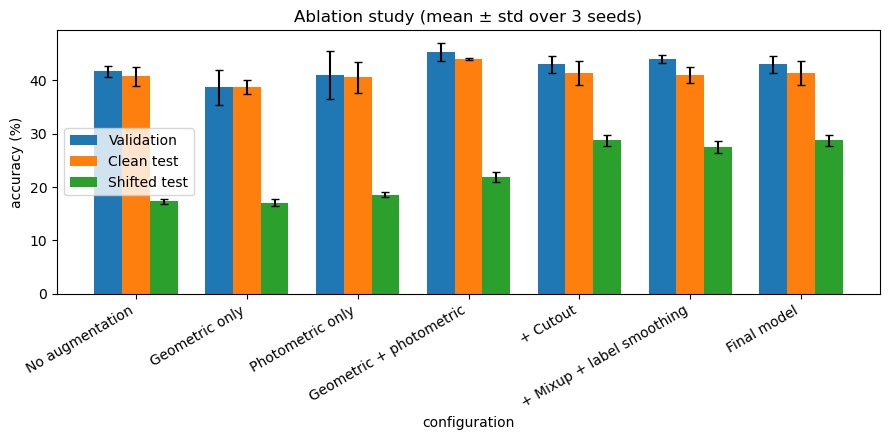

In [44]:
x = np.arange(len(names))
width = 0.25

plt.figure(figsize=(9, 4.5))
for i, (key, label) in enumerate([("val", "Validation"), ("clean", "Clean test"), ("shifted", "Shifted test")]):
    means = [np.mean(ablation[n][key]) * 100 for n in names]
    stds = [np.std(ablation[n][key]) * 100 for n in names]
    plt.bar(x + (i - 1) * width, means, width, yerr=stds, capsize=3, label=label)

plt.xticks(x, names, rotation=30, ha='right')
plt.xlabel('configuration')
plt.ylabel('accuracy (%)')
plt.title('Ablation study (mean ± std over 3 seeds)')
plt.legend()
plt.tight_layout()
plt.show()

# Conclusion

Data augmentation helps the model on shifted test images when it trains on changes similar to those found in the test set. The results clearly show this.

**Without augmentation** the shifted-test accuracy was 17.34% ± 0.43%. Geometric augmentation alone did not improve the result much, giving 17.09% ± 0.69%, a decrease of 0.25 percentage points. Photometric augmentation alone gave a small improvement, raising accuracy to 18.58% ± 0.41%, a gain of 1.24 points. However, combining both methods increased accuracy to 21.91% ± 0.96%, a gain of 4.57 points over no augmentation. This is because the shifted test images contain several changes at once, including rotation, brightness and contrast changes, blur, noise, and colour changes. Training with both types of augmentation helps the model learn to handle these changes together.

**The biggest improvement came from adding Cutout**. It increased accuracy by 6.86 percentage points, bringing it to 28.77% ± 0.99%. This is an overall improvement of 11.43 points compared to using no augmentation. The improvement makes sense because the shifted test set contains random rectangular occlusions, where a 16×16 patch, covering about 25% of the image, is blacked out. Cutout works similarly by hiding random patches in training images. This forces the model to learn from the remaining parts of an object instead of depending on just one area. The improvement is much larger than the variation between training runs, which is about one percentage point, suggesting that it is a meaningful improvement rather than random noise. Clean-test accuracy changes only slightly across the different configurations, ranging from 40.74% to 43.99%. This suggests that Cutout mainly improves performance on shifted images.

**Mixup and label smoothing did not provide further improvement**. After adding them, accuracy decreased to 27.49% ± 1.05%, a drop of 1.28 percentage points compared to Cutout alone. This difference is close to the variation between runs, so the two results are roughly similar. One possible reason is that none of the test corruptions involves blending two images, while Mixup makes the learning task more difficult for a small model.

**Final model selection:** The final model was selected using validation accuracy before evaluating the test sets. The three candidate models achieved validation accuracies of 45.33%, 43.00%, and 44.00%. Since the validation set contains only 100 images, these results fall within approximately one standard error of each other, around five percentage points. Therefore, the candidates were treated as tied, and the fixed tie-breaking order specified in the task was used to select the model with Cutout.

# PART E

### predictions of the final model (seed 0)

In [45]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

model = final_models[0]

pred_clean = np.argmax(model.predict(X_clean, verbose=0), axis=1)
pred_shift = np.argmax(model.predict(X_shift, verbose=0), axis=1)

print("Clean accuracy:  ", np.mean(pred_clean == clean_y))
print("Shifted accuracy:", np.mean(pred_shift == shift_y))

Clean accuracy:   0.4217
Shifted accuracy: 0.2941


### E1: accuracy for each class

In [46]:
clean_per_class = []
shift_per_class = []

print(f"{'class':<12}{'clean':>8}{'shifted':>10}{'drop':>8}")
for c in range(10):
    acc_clean = np.mean(pred_clean[clean_y == c] == c) * 100
    acc_shift = np.mean(pred_shift[shift_y == c] == c) * 100
    clean_per_class.append(acc_clean)
    shift_per_class.append(acc_shift)
    print(f"{class_names[c]:<12}{acc_clean:>7.1f}%{acc_shift:>9.1f}%{acc_shift - acc_clean:>+8.1f}")

order = np.argsort(shift_per_class)
print("\nBest shifted classes: ", [class_names[i] for i in order[::-1][:3]])
print("Worst shifted classes:", [class_names[i] for i in order[:3]])
drops = np.array(shift_per_class) - np.array(clean_per_class)
print("Biggest drops (clean -> shifted):", [class_names[i] for i in np.argsort(drops)[:3]])

class          clean   shifted    drop
airplane       54.0%     41.8%   -12.2
automobile     46.5%     43.7%    -2.8
bird           12.0%      9.8%    -2.2
cat             8.3%     10.9%    +2.6
deer           32.5%     27.3%    -5.2
dog            45.5%     29.0%   -16.5
frog           68.8%     46.4%   -22.4
horse          58.5%     19.0%   -39.5
ship           33.5%     28.9%    -4.6
truck          62.1%     37.3%   -24.8

Best shifted classes:  ['frog', 'automobile', 'airplane']
Worst shifted classes: ['bird', 'cat', 'horse']
Biggest drops (clean -> shifted): ['horse', 'truck', 'frog']


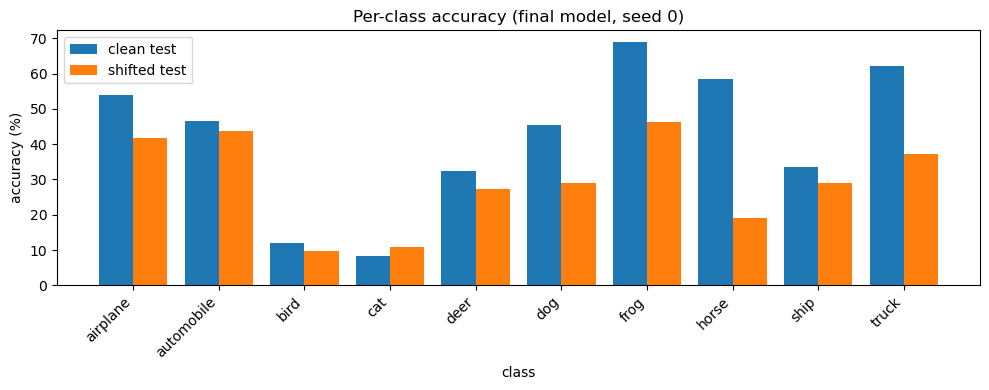

In [47]:
x = np.arange(10)
plt.figure(figsize=(10, 4))
plt.bar(x - 0.2, clean_per_class, 0.4, label='clean test')
plt.bar(x + 0.2, shift_per_class, 0.4, label='shifted test')
plt.xticks(x, class_names, rotation=45, ha='right')
plt.xlabel('class')
plt.ylabel('accuracy (%)')
plt.title('Per-class accuracy (final model, seed 0)')
plt.legend()
plt.tight_layout()
plt.show()

### E1: normalized confusion matrix (shifted test)

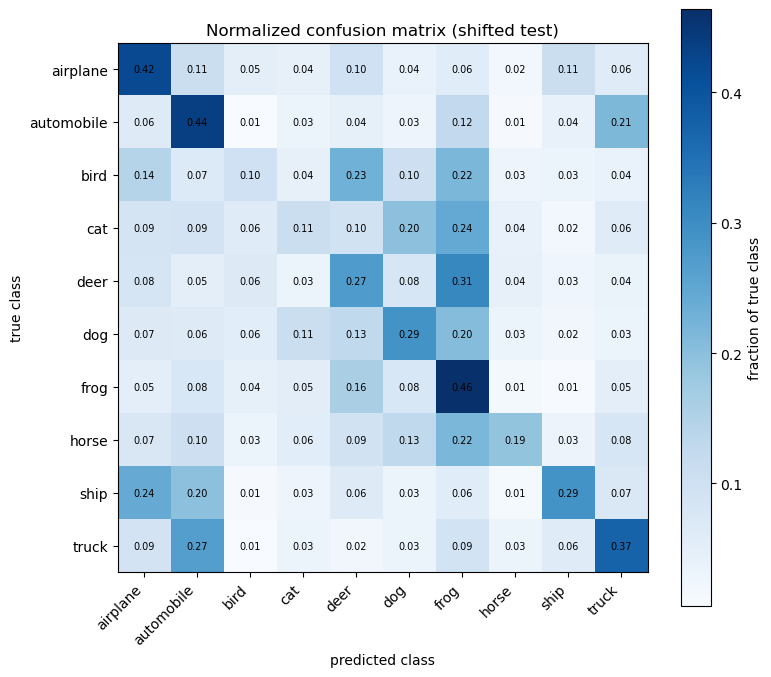

Most frequent confusions (fraction of the true class):
        deer predicted as frog        31.0%
       truck predicted as automobile  26.6%
         cat predicted as frog        24.4%
        ship predicted as airplane    24.1%
        bird predicted as deer        22.9%
        bird predicted as frog        21.7%
       horse predicted as frog        21.6%
  automobile predicted as truck       21.5%

Most predicted class on the shifted test: frog (19.9% of all predictions, 10% would be balanced)


In [49]:
cm = confusion_matrix(shift_y, pred_shift, normalize='true')   # each row sums to 1

plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap='Blues')
plt.colorbar(label='fraction of true class')

plt.xticks(range(10), class_names, rotation=45, ha='right')
plt.yticks(range(10), class_names)

for i in range(10):
    for j in range(10):
        plt.text(j, i, f"{cm[i, j]:.2f}", ha='center', va='center', fontsize=7,
                 color='white' if cm[i, j] > 0.5 else 'black')

plt.xlabel('predicted class')
plt.ylabel('true class')
plt.title('Normalized confusion matrix (shifted test)')
plt.tight_layout()
plt.show()

# E2: the most frequent confusions (true class vs predicted class)
off = cm.copy()
np.fill_diagonal(off, 0)
print("Most frequent confusions (fraction of the true class):")
for flat in np.argsort(off.ravel())[::-1][:8]:
    i, j = divmod(flat, 10)
    print(f"  {class_names[i]:>10} predicted as {class_names[j]:<10} {off[i, j]*100:5.1f}%")

# which class is predicted most often 
counts = np.bincount(pred_shift, minlength=10)
print("\nMost predicted class on the shifted test:", class_names[int(np.argmax(counts))],
      f"({counts.max() / len(pred_shift) * 100:.1f}% of all predictions, 10% would be balanced)")

### E3: eight misclassified images

Image indices: [3773 4276 4154 1238 4421 1811 3260 6536]


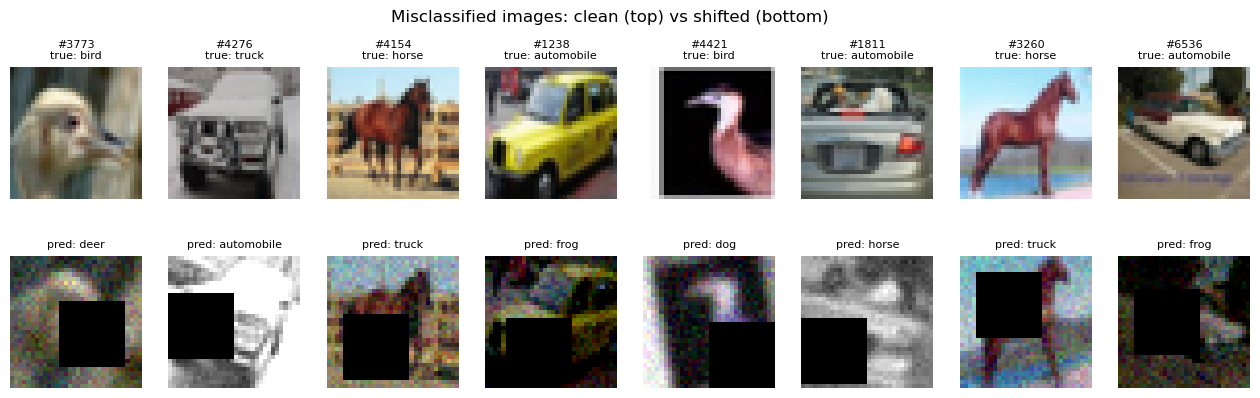

In [50]:
wrong = np.where(pred_shift != shift_y)[0]       # indices of mistakes
rng = np.random.RandomState(0)                    # fixed seed, same 8 every time
chosen = rng.choice(wrong, 8, replace=False)
print("Image indices:", chosen)

plt.figure(figsize=(16, 4.5))
for k, i in enumerate(chosen):
    plt.subplot(2, 8, k + 1)
    plt.imshow(clean_x[i])
    plt.title(f"#{i}\ntrue: {class_names[shift_y[i]]}", fontsize=8)
    plt.axis('off')

    plt.subplot(2, 8, k + 9)
    plt.imshow(shift_x[i])
    plt.title(f"pred: {class_names[pred_shift[i]]}", fontsize=8)
    plt.axis('off')

plt.suptitle('Misclassified images: clean (top) vs shifted (bottom)')
plt.show()

### E4: hidden-corruption test (only the unlisted corruption, on the clean test set)

In [51]:
def make_grayscale(images):
    gray = images.mean(axis=3, keepdims=True)
    return np.repeat(gray, 3, axis=3)

def make_channel_swap(images, seed=5):
    r = np.random.RandomState(seed)
    out = images.copy()
    for i in range(len(out)):
        out[i] = out[i][:, :, r.permutation(3)]       # random order of R, G, B
    return out

def make_hidden(images, seed=7):
    # the same hidden orruption used 
    r = np.random.RandomState(seed)
    return np.array([hidden_corruption(im.astype(np.float32), r) for im in images])

def make_inverted(images):
    return 255 - images                               # negative image

tests = {
    "Clean (no corruption)":              clean_x / 255.0,
    "Hidden corruption only":             make_hidden(clean_x) / 255.0,
    "Grayscale on every image":           make_grayscale(clean_x) / 255.0,
    "Channel swap on every image":        make_channel_swap(clean_x) / 255.0,
    "Inverted colours (never trained)":   make_inverted(clean_x) / 255.0,
}

hidden_results = {}
print("Accuracy on clean test images with only one corruption (final model, mean ± std over 3 seeds)\n")

for name, X in tests.items():
    accs = [m.evaluate(X, clean_y_oh, verbose=0)[1] for m in final_models]
    hidden_results[name] = (np.mean(accs) * 100, np.std(accs) * 100)
    print(f"{name:<36}{np.mean(accs)*100:6.2f} ± {np.std(accs)*100:.2f} %")

Accuracy on clean test images with only one corruption (final model, mean ± std over 3 seeds)

Clean (no corruption)                41.40 ± 2.21 %
Hidden corruption only               37.74 ± 2.88 %
Grayscale on every image             36.14 ± 4.06 %
Channel swap on every image          32.72 ± 2.85 %
Inverted colours (never trained)     12.66 ± 1.89 %


## Reasoning (Part E)

**E1. Per-class accuracy**

Some classes are difficult because the model does not learn them well from the start, while others become harder when image corruptions hide important features.

On the shifted test set, the model performs best on frog (46.4%), automobile (43.7%), and airplane (41.8%). It performs worst on bird (9.8%), cat (10.9%), and horse (19.0%). Bird and cat already have low accuracy on clean images (12.0% and 8.3%), so the problem is not only caused by corruptions. Since there are only 40 training images per class, the model struggles to learn these classes properly. The small 2.6-point improvement for cat is likely just random variation because its accuracy is already close to guessing.

The biggest drops from clean to shifted images are seen for horse (−39.5 points), truck (−24.8 points), and frog (−22.4 points). For example, a horse can be recognised by its legs, neck, and head, but rotation and the black square can hide these features. Automobile accuracy barely changes, dropping by only 2.8 points. These results come from seed 0, so some differences may be due to random variation.

**E2. Most confused classes**

The model makes mistakes mainly for two reasons: some classes look similar, and the model sometimes predicts the same class when an image becomes too unclear.

**Similar-looking classes:** The model often confuses trucks with automobiles (truck automobile: 26.6%, automobile  truck: 21.5%) and ships with airplanes (ship  airplane: 24.1%). Trucks and cars share features such as wheels and road backgrounds, while ships and airplanes may have similar blue-grey backgrounds from water and sky. Because the images are only 32×32 pixels and there are just 400 training images, the model struggles to learn the small details that separate these classes.

**Frog as a common guess:** Frog makes up 19.9% of all predictions, even though it would be expected to account for around 10% if predictions were evenly distributed. The model often mistakes deer (31.0%), cats (24.4%), birds (21.7%), and horses (21.6%) for frogs. One possible explanation is that darkness, noise, and the black square make images look dark and textured, which the model associates with frogs. This is only an interpretation, not something directly tested, but the dark misclassified images in E3 support this idea.

**Similar outdoor scenes:** The model also confuses birds with deer (22.9%). Both can appear in similar brown and green outdoor environments, making them harder to tell apart.

**E3. Eight misclassified images**

In these examples, the black square hides important parts of the object, while noise, darkness, blur, or colour changes make the remaining parts harder to recognise.

| Image # | Actual class | Predicted class | Why the model made the mistake                                                                                                                         |
| ------- | ------------ | --------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------ |
| 3773    | Bird         | Deer            | The square hides part of the head and neck. The remaining image looks like a blurry brown shape, and the beak is difficult to see.                     |
| 4276    | Truck        | Automobile      | The image is too bright and has low contrast. The square also hides the front grille, which could help identify the truck.                             |
| 4154    | Horse        | Truck           | The square hides the legs, making the horse's body look like a brown box against the fence.                                                            |
| 1238    | Automobile   | Frog            | The image is dark and noisy, making the yellow taxi look dark greenish-brown. The square also hides the front of the car.                              |
| 4421    | Bird         | Dog             | The square blends into the black background, while blur and rotation make the head difficult to recognise. The beak is no longer clear.                |
| 1811    | Automobile   | Horse           | The image has lost its colour and has low contrast. The square also hides the rear and wheel, making the car harder to identify.                       |
| 3260    | Horse        | Truck           | The square hides the head and neck, which are important features for recognising a horse. Noise and colour changes make the remaining parts confusing. |
| 6536    | Automobile   | Frog            | The image is almost completely black, and the square hides most of the car. With very little information available, the model predicts frog.           |

The two darkest images, 1238 and 6536, were both predicted as frogs. This supports the pattern discussed in E2, where the model often guesses frog when images become too dark or unclear.

**E4. Hidden-corruption test**

If data augmentation helps the model handle colour changes, its accuracy on images with this corruption should remain close to its accuracy on clean images.

On clean images, the model achieves 41.40% ± 2.21% accuracy. When only the hidden corruption is applied, accuracy drops to 37.74% ± 2.88%, a decrease of 3.66 percentage points. This means the model keeps about 91% of its clean-image accuracy. The drop is also similar in size to the variation between training runs, suggesting that the model handles this corruption reasonably well.

However, the hidden corruption is applied to only about half of the images. When grayscale is applied to every image, accuracy is 36.14% ± 4.06%. When the colour channels are swapped for every image, accuracy falls further to 32.72% ± 2.85%.

Channel swapping causes the biggest drop because colour can help the model recognise objects. For example, frogs are often green, while airplanes and ships may appear against blue skies or water. Grayscale removes colour too, but it keeps the object's shape and texture. This may explain why grayscale performs better than swapping the colour channels.

# PART F

### helper functions ( N = 6)

In [52]:
# shift the images by dx, dy pixels 
def shift_images(X, dx, dy):
    padded = np.pad(X, ((0, 0), (2, 2), (2, 2), (0, 0)), mode='reflect')
    return padded[:, 2 + dy:34 + dy, 2 + dx:34 + dx, :]

# the augmented copies of the test images (N = 6)
def make_versions(X):
    return [
        X,                              # 1. original
        X[:, :, ::-1, :],               # 2. horizontal flip
        shift_images(X, 2, 0),          # 3. shift right
        shift_images(X, -2, 0),         # 4. shift left
        shift_images(X, 0, 2),          # 5. shift down
        shift_images(X, 0, -2),         # 6. shift up
    ]

# average the softmax outputs over all copies
def tta_predict(model, X):
    total = np.zeros((len(X), 10))
    versions = make_versions(X)
    for v in versions:
        total += model.predict(np.ascontiguousarray(v), verbose=0)
    return total / len(versions)

### compare normal prediction vs TTA (shifted test, final model)

In [55]:
normal_acc, tta_acc = [], []
normal_time, tta_time = [], []

final_models[0].predict(X_shift[:100], verbose=0)   

for i, m in enumerate(final_models):
    t = time.time()
    p = m.predict(X_shift, verbose=0)
    normal_time.append(time.time() - t)
    normal_acc.append(np.mean(np.argmax(p, axis=1) == shift_y))

    t = time.time()
    p = tta_predict(m, X_shift)
    tta_time.append(time.time() - t)
    tta_acc.append(np.mean(np.argmax(p, axis=1) == shift_y))

    print(f"Seed {seeds[i]}: normal={normal_acc[-1]*100:.2f}%  TTA={tta_acc[-1]*100:.2f}%")

Seed 0: normal=29.41%  TTA=29.52%
Seed 1: normal=27.37%  TTA=27.42%
Seed 2: normal=29.53%  TTA=29.62%


### results

In [56]:
normal_acc = np.array(normal_acc) * 100
tta_acc = np.array(tta_acc) * 100

print("Shifted-test accuracy (mean ± std over 3 seeds)")
print(f"  Without TTA: {normal_acc.mean():.2f} ± {normal_acc.std():.2f} %")
print(f"  With TTA:    {tta_acc.mean():.2f} ± {tta_acc.std():.2f} %")
print(f"  Change:      {tta_acc.mean() - normal_acc.mean():+.2f} points")

print(f"\nInference cost ({len(X_shift)} images)")
print(f"  Without TTA: {np.mean(normal_time):.2f} sec")
print(f"  With TTA:    {np.mean(tta_time):.2f} sec")
print(f"  Slower by:   {np.mean(tta_time) / np.mean(normal_time):.1f}x")

Shifted-test accuracy (mean ± std over 3 seeds)
  Without TTA: 28.77 ± 0.99 %
  With TTA:    28.85 ± 1.01 %
  Change:      +0.08 points

Inference cost (10000 images)
  Without TTA: 7.18 sec
  With TTA:    47.25 sec
  Slower by:   6.6x


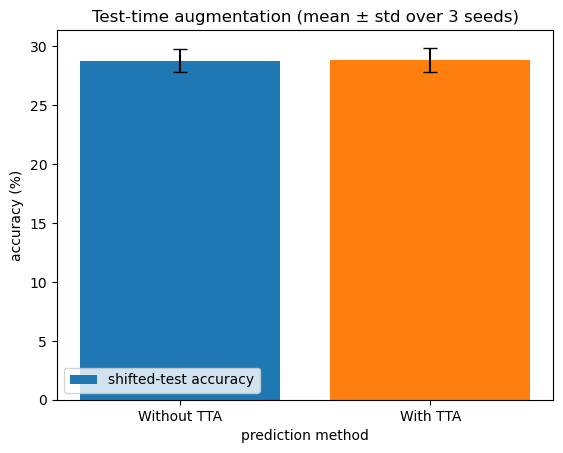

In [57]:
plt.bar(['Without TTA', 'With TTA'],
        [normal_acc.mean(), tta_acc.mean()],
        yerr=[normal_acc.std(), tta_acc.std()], capsize=5,
        color=['tab:blue', 'tab:orange'], label='shifted-test accuracy')
plt.xlabel('prediction method')
plt.ylabel('accuracy (%)')
plt.title('Test-time augmentation (mean ± std over 3 seeds)')
plt.legend()
plt.show()

# Conclusion

## Conclusion (Part F: Test-Time Augmentation)

**Test-Time Augmentation (TTA) works** by making several slightly different versions of the same image and averaging the model's predictions. It can help when the model makes different mistakes on different versions, because averaging can reduce those mistakes. However, it does not help much when all versions have the same problem.

For this experiment, I averaged the model's predictions across 6 versions of each shifted-test image: the original image, a horizontal flip, and four shifts of 2 pixels (left, right, up, and down). These versions were decided in advance, without tuning anything using the test data.

**Results:** The shifted-test accuracy increased slightly from 28.77% ± 0.99% to 28.85% ± 1.01%, a gain of only 0.08 percentage points. All three seeds showed a small improvement (+0.11, +0.05, and +0.09 points), but these gains represent only about 5 to 11 additional correct predictions out of 10,000 images. Therefore, TTA did not provide a meaningful improvement.

**Why was the improvement so small?** The main problems in the shifted test images are the black square covering part of the image, changes in brightness and contrast, and noise. Flipping or shifting an image by 2 pixels does not fix these problems. Every version still contains the same black square and noise, so the model tends to make the same mistakes. Also, the model was already trained with flips and shifts, so these extra versions do not provide much new information.

**Inference cost:** Without TTA, processing 10,000 images took 7.18 seconds. With TTA, it took 47.25 seconds, making inference about 6.6 times slower. This is expected because the model processes six versions of each image instead of just one.
Although TTA does not require additional training, its computational cost increases with the number of image versions. In this experiment, the extra cost was not worth the tiny improvement of 0.08 percentage points.